# USD / SLE: a simple stochastic forecast from first principles

**Question.** How many new leones (SLE) will one US dollar cost over the next 12 months, how uncertain is that,
and what does the uncertainty mean for matching remittance flows with investors who need dollars?

**The whole model in one line**

$$\ln S_{t+\Delta t} = \ln S_t + \mu\,\Delta t + \sigma\sqrt{\Delta t}\;\varepsilon_t,\qquad \varepsilon_t \sim N(0,1),\quad \Delta t = \tfrac{1}{252}$$

* $S_t$ = leones per dollar on trading day $t$
* $\mu$ = **drift**: how fast the leone weakens per year. Set by the **inflation gap** between Sierra Leone and the US.
* $\sigma$ = **volatility**: how big the random surprises are per year. Measured from **monthly** moves in the past 3 years.
* $\varepsilon_t$ = a fresh random number each day.

Two numbers per currency ($\mu$ and $\sigma$) plus today's rate $S_0$. Nothing else is estimated.

**Method:** we generate **10,000 Monte Carlo paths** of this equation (one random $\varepsilon$ per day per path) and read every forecast, probability and liquidity measure off those paths. The closed-form solution of the same equation is used to check the Monte Carlo code. The random surprises $\varepsilon_t$
can be drawn from a normal distribution (default), a **Student t-distribution** (fatter tails) or by **bootstrap** (resampling
real past moves); Section 11b compares the three.

## The role of inflation (read this first)

**Intuition.** An exchange rate is the price of one money in terms of another. If prices in Sierra Leone rise by 15.7% a year
and prices in the US by 3.7%, the leone loses purchasing power about 11% a year faster than the dollar. For the same basket of goods
to cost about the same in both countries, a dollar has to cost more leones over time. Inflation therefore tells us the
**direction and speed** of the currency's long-run drift.

**Formula (relative purchasing power parity, PPP).** Let a basket of goods cost $P_{SL}$ leones in Sierra Leone and $P_{US}$ dollars
in the US. PPP says the exchange rate keeps the basket equally priced, $S = P_{SL}/P_{US}$. After one year each price level has grown
by its inflation rate, so

$$\frac{S_1}{S_0} = \frac{1+\pi_{SL}}{1+\pi_{US}}
\quad\Longrightarrow\quad
\mu = \ln(1+\pi_{SL}) - \ln(1+\pi_{US})$$

**Example (live forecast, Nov 2026).** $\pi_{SL} = 15.66\%$, $\pi_{US} = 3.7\%$:
$\mu = \ln 1.1566 - \ln 1.037 = 0.1455 - 0.0363 = 0.109$, i.e. the leone is expected to weaken by about **10.9% a year**.
A rate of 24.0 today gives a middle forecast of $24.0 \times e^{0.109} \approx 26.8$ in one year.

| Inflation sets | Inflation does **not** set |
|---|---|
| the middle forecast: its direction and speed (drift $\mu$) | the width of the range (volatility $\sigma$, from past monthly moves) |

**Why inflation and not the past trend?**
1. **Economic reason:** the drift comes from a mechanism (loss of purchasing power), not from extrapolating a chart.
   The past SLE trend is dominated by one-off crises (2017, 2020, 2023); extrapolating it is what made the old model biased upwards.
2. **No look-ahead:** inflation is published monthly, so at any forecast date we know exactly which figure was available.
3. **Adaptability:** every EMDE publishes inflation, so moving the model to a new currency means changing one number.

**Where it fails.** PPP is a long-run anchor. Over months, currencies often move against the inflation gap (central bank intervention,
aid inflows, a peg, a policy reset). The *No drift* benchmark in Sections 10–11 measures whether inflation helps in practice.

**Contents**

| Part | Sections | What it does |
|---|---|---|
| 1. Data | 1–5 | download, clean, splice and freeze the daily USD/SLE series |
| 2. Model | 6–9 | formulas, inflation inputs, fitting |
| 3. Does it work? | 10–11b | out-of-sample test 2025–26, a 28-date backtest, and normal vs t vs bootstrap shocks |
| 4. Risk & liquidity | 12–14 | stress jumps, trigger probabilities, matching remittances with investors, guarantee losses |
| 5. Forecast | 15–16 | 12-month and 5-year forecasts from 6 Nov 2026, exported to CSV |
| 6. Other currencies | 17 | the same code on GHS, NGN, KES |
| 7. Limits | 18 | recalibration checklist and honest weaknesses |

# Part 1. Data

Downloads daily USD → Sierra Leonean leone rates as CSV files, parses them, merges them into one series and plots it.

**Redenomination:** on 1 July 2022 Sierra Leone swapped the old leone (SLL) for the new leone (SLE) at **1 SLE = 1000 SLL**.
All values below are in **new leones (SLE) per 1 USD**. Pre‑2022 SLL quotes are divided by 1000 so the series is continuous.

**Sources** (no single free source covers the whole period):

| Period | Source | Why |
|---|---|---|
| 2015‑01‑01 → day before Wise data starts | Yahoo Finance `SLL=X` | long history, but the quote freezes at 19,700 from Feb 2023 |
| last 5 years → today | Wise public rate history (`USD→SLL`) | live mid‑market rate; the endpoint only goes back 5 years |

Where the two overlap (Nov 2021 – Jan 2023) they agree within about 1.5%.

**Frozen data:** the analysis runs on a fixed snapshot of the raw CSVs in `data/`, ending on **6 Nov 2026** (`DATA_END`).
`REFRESH = False` by default, so rerunning gives the same numbers. A manifest (`data/snapshot_manifest.json`) stores a
SHA-256 hash of every file and the notebook checks it on each run. Set `REFRESH = True` only to deliberately pull new data.

In [95]:
from pathlib import Path
from datetime import date
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

START = "2015-01-01"
TODAY = date.today().isoformat()
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

RAW_YAHOO = DATA_DIR / "usd_sll_yahoo_raw.csv"
RAW_WISE = DATA_DIR / "usd_sll_wise_raw.csv"
MERGED = DATA_DIR / "usd_sle_daily.csv"

REFRESH = False      # True = re-download everything (breaks the frozen snapshot)
DATA_END = "2026-11-06"  # last trading day in the frozen snapshot; all analysis stops here
MANIFEST = DATA_DIR / "snapshot_manifest.json"
N_PATHS = 10_000   # simulated futures per forecast
SEED = 7
HEADERS = {"User-Agent": "Mozilla/5.0 (currency-notebook)"}
print(f"Range: {START} → {DATA_END}  (REFRESH={REFRESH})")

Range: 2015-01-01 → 2026-11-06  (REFRESH=False)


## 1. Download raw data and save it as CSV

In [123]:
def download_yahoo_csv(symbol: str, start: str, path: Path) -> None:
    """Daily closes from Yahoo's chart API, written as date,close CSV."""
    p1 = int(pd.Timestamp(start, tz="UTC").timestamp())
    p2 = int(pd.Timestamp.now(tz="UTC").timestamp())
    url = f"https://query1.finance.yahoo.com/v8/finance/chart/{symbol}"
    r = requests.get(url, params={"period1": p1, "period2": p2, "interval": "1d"},
                     headers=HEADERS, timeout=30)
    r.raise_for_status()
    res = r.json()["chart"]["result"][0]
    df = pd.DataFrame({
        "date": pd.to_datetime(res["timestamp"], unit="s").date,
        "close": res["indicators"]["quote"][0]["close"],
    })
    df.to_csv(path, index=False)


def download_wise_csv(source: str, target: str, path: Path) -> None:
    """Daily mid-market rates from Wise (max 5 years back), written as date,close CSV."""
    url = "https://wise.com/rates/history+live"
    params = {"source": source, "target": target, "length": 5,
              "resolution": "daily", "unit": "year"}
    r = requests.get(url, params=params, headers=HEADERS, timeout=30)
    r.raise_for_status()
    df = pd.DataFrame(r.json())
    df = pd.DataFrame({
        "date": pd.to_datetime(df["time"], unit="ms").dt.date,
        "close": df["value"],
    })
    df.to_csv(path, index=False)


if REFRESH or not RAW_YAHOO.exists():
    download_yahoo_csv("SLL=X", START, RAW_YAHOO)
if REFRESH or not RAW_WISE.exists():
    download_wise_csv("USD", "SLL", RAW_WISE)

for p in (RAW_YAHOO, RAW_WISE):
    print(p, f"{p.stat().st_size:,} bytes")

data\usd_sll_yahoo_raw.csv 56,456 bytes
data\usd_sll_wise_raw.csv 36,552 bytes


## 2. Parse the CSVs

In [97]:
def read_rate_csv(path: Path) -> pd.Series:
    df = pd.read_csv(path, parse_dates=["date"])
    s = (df.dropna(subset=["close"])
           .groupby("date")["close"].last()   # one value per day (the live tick duplicates today)
           .sort_index())
    return s / 1000  # SLL -> SLE

yahoo = read_rate_csv(RAW_YAHOO)
wise = read_rate_csv(RAW_WISE)

print(f"Yahoo: {len(yahoo):5,} rows  {yahoo.index.min().date()} → {yahoo.index.max().date()}")
print(f"Wise:  {len(wise):5,} rows  {wise.index.min().date()} → {wise.index.max().date()}")

Yahoo: 2,457 rows  2015-01-01 → 2026-11-08
Wise:  1,827 rows  2021-11-08 → 2026-11-08


## 3. Clean and merge

* **Despike:** Yahoo's history has bad ticks (e.g. 0.001 or 0.042 SLE). A point that is more than 5% away from its centred
  11‑day rolling median is dropped.
* **Splice:** Yahoo up to the day before Wise starts, Wise from then on.

In [98]:
def despike(s: pd.Series, window: int = 11, tol: float = 0.05) -> pd.Series:
    med = s.rolling(window, center=True, min_periods=3).median()
    keep = (s / med - 1).abs() <= tol
    print(f"  {s.name}: dropped {(~keep).sum()} spikes")
    return s[keep]

yahoo.name, wise.name = "yahoo", "wise"
yahoo_clean = despike(yahoo)
wise_clean = despike(wise)

splice_date = wise_clean.index.min()
rate = pd.concat([
    yahoo_clean[(yahoo_clean.index >= START) & (yahoo_clean.index < splice_date)].to_frame("usd_sle").assign(source="yahoo"),
    wise_clean.to_frame("usd_sle").assign(source="wise"),
])
rate.index.name = "date"
rate["usd_sle"] = rate["usd_sle"].round(5)

rate.to_csv(MERGED)
print(f"\nSaved {MERGED}: {len(rate):,} daily rows, {rate.index.min().date()} → {rate.index.max().date()}")
print(f"Splice at {splice_date.date()}")
rate.tail()

  yahoo: dropped 30 spikes
  wise: dropped 0 spikes

Saved data\usd_sle_daily.csv: 3,574 daily rows, 2015-01-01 → 2026-11-08
Splice at 2021-11-08


,usd_sle,source
date,,
2026-11-04,23.4099,wise
2026-11-05,23.4099,wise
2026-11-06,23.4239,wise
2026-11-07,23.4413,wise
2026-11-08,23.4413,wise


## 3b. Freeze the data snapshot

**Problem:** Yahoo and Wise are unofficial endpoints. Their history can change or disappear, so a live download
is not reproducible.

**What we are doing:** saving a manifest with the size, date range and SHA-256 hash of every data file. On later runs
(with `REFRESH = False`) the notebook recomputes the hashes and stops if any file has changed.

**Why:** anyone reproducing the model gets exactly our numbers, or a clear error telling them the data is different.

In [99]:
import hashlib
import json


def sha256(path: Path) -> str:
    return hashlib.sha256(path.read_bytes()).hexdigest()


def file_info(path: Path) -> dict:
    df = pd.read_csv(path)
    return {"sha256": sha256(path), "rows": len(df),
            "first_date": str(df.iloc[0, 0]), "last_date": str(df.iloc[-1, 0])}


snapshot_files = [RAW_YAHOO, RAW_WISE, MERGED]

if REFRESH or not MANIFEST.exists():
    manifest = {"created": TODAY, "data_end": DATA_END,
                "files": {p.name: file_info(p) for p in snapshot_files}}
    MANIFEST.write_text(json.dumps(manifest, indent=2))
    print(f"New snapshot written to {MANIFEST}")
else:
    manifest = json.loads(MANIFEST.read_text())
    for p in snapshot_files:
        expected = manifest["files"][p.name]["sha256"]
        if sha256(p) != expected:
            raise RuntimeError(f"{p.name} differs from the frozen snapshot. "
                               "Restore the original file or set REFRESH = True on purpose.")
    print(f"Snapshot verified: {len(snapshot_files)} files match {MANIFEST.name} (created {manifest['created']})")

pd.DataFrame(manifest["files"]).T[["rows", "first_date", "last_date"]]

Snapshot verified: 3 files match snapshot_manifest.json (created 2026-11-08)


,rows,first_date,last_date
usd_sll_yahoo_raw.csv,3093,2015-01-01,2026-11-08
usd_sll_wise_raw.csv,1827,2021-11-08,2026-11-08
usd_sle_daily.csv,3574,2015-01-01,2026-11-08
usd_ghs_wise_raw.csv,1827,2021-11-08,2026-11-08
usd_ngn_wise_raw.csv,1827,2021-11-08,2026-11-08
usd_kes_wise_raw.csv,1827,2021-11-08,2026-11-08


## 4. Read back the merged CSV and summarise

In [100]:
rate = pd.read_csv(MERGED, parse_dates=["date"], index_col="date")
s = rate["usd_sle"]

yearly = pd.DataFrame({
    "first": s.resample("YE").first(),
    "last": s.resample("YE").last(),
    "mean": s.resample("YE").mean(),
    "min": s.resample("YE").min(),
    "max": s.resample("YE").max(),
})
yearly["change_%"] = (yearly["last"] / yearly["first"] - 1) * 100
yearly.index = yearly.index.year
yearly.round(2)

,first,last,mean,min,max,change_%
date,,,,,,
2015,4.19,4.36,4.33,3.96,5.00,3.86
2016,4.11,5.52,4.97,3.86,6.90,34.59
2017,5.52,7.60,7.44,5.52,7.66,37.65
2018,7.60,8.60,7.93,7.54,8.60,13.16
2019,8.60,9.68,9.00,8.40,9.68,12.50
2020,9.68,10.04,9.72,9.23,10.06,3.77
2021,10.04,11.36,10.39,10.03,11.36,13.16
2022,11.25,18.90,14.02,11.25,18.90,68.00
2023,18.90,22.82,21.38,18.02,23.05,20.72


## 5. Chart

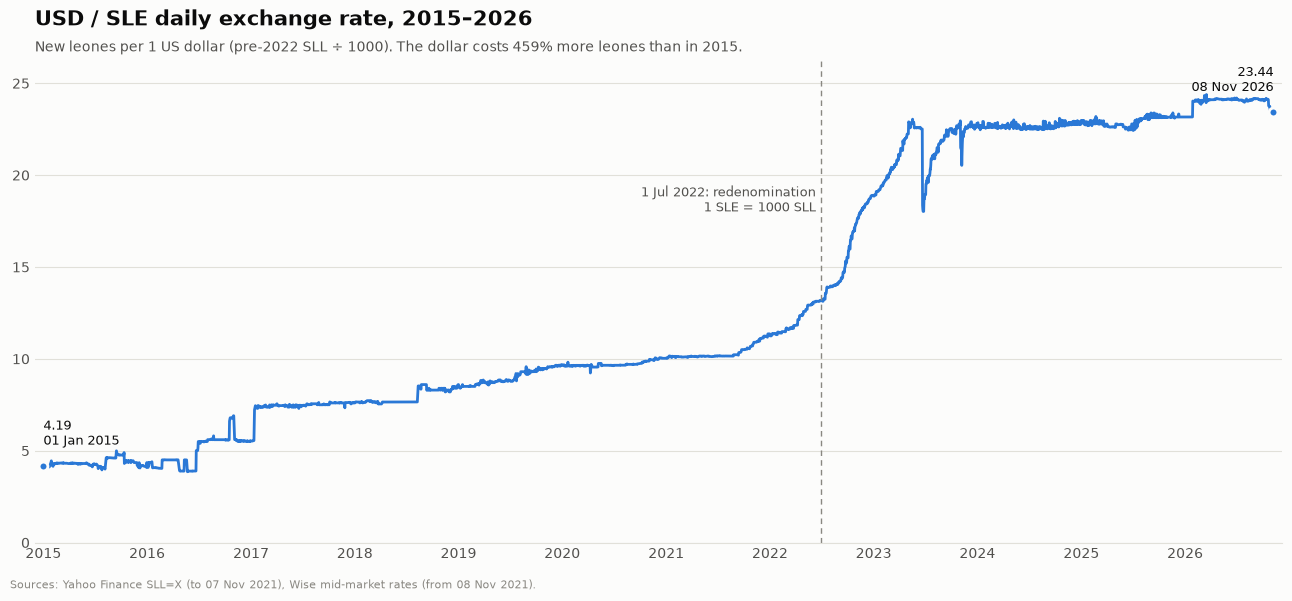

In [101]:
# palette: single series -> slot-1 blue, recessive chrome
SERIES = "#2a78d6"; INK = "#0b0b0b"; INK2 = "#52514e"; MUTED = "#898781"; GRID = "#e1e0d9"; SURFACE = "#fcfcfb"

fig, ax = plt.subplots(figsize=(13, 6), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
ax.plot(s.index, s.values, color=SERIES, linewidth=2)

# redenomination marker
redenom = pd.Timestamp("2022-07-01")
ax.axvline(redenom, color=MUTED, linewidth=1, linestyle=(0, (4, 3)))
ax.text(redenom - pd.Timedelta(days=20), s.max() * 0.8, "1 Jul 2022: redenomination\n1 SLE = 1000 SLL",
        color=INK2, fontsize=9, va="top", ha="right")

# label first and last values only
first_d, first_v = s.index[0], s.iloc[0]
last_d, last_v = s.index[-1], s.iloc[-1]
for d, v, ha in [(first_d, first_v, "left"), (last_d, last_v, "right")]:
    ax.scatter([d], [v], s=40, color=SERIES, edgecolor=SURFACE, linewidth=2, zorder=3)
    ax.annotate(f"{v:.2f}\n{d:%d %b %Y}", (d, v), xytext=(0, 12), textcoords="offset points",
                ha=ha, va="bottom", fontsize=9, color=INK)

growth = (last_v / first_v - 1) * 100
ax.set_title(f"USD / SLE daily exchange rate, {first_d.year}–{last_d.year}", loc="left",
             fontsize=15, color=INK, fontweight="bold", pad=24)
ax.text(0, 1.015, f"New leones per 1 US dollar (pre-2022 SLL ÷ 1000). The dollar costs {growth:,.0f}% more leones than in {first_d.year}.",
        transform=ax.transAxes, fontsize=10, color=INK2)

ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}"))
ax.set_ylim(0, s.max() * 1.08)
ax.set_xlim(s.index[0] - pd.Timedelta(days=30), s.index[-1] + pd.Timedelta(days=30))
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.tick_params(colors=MUTED, labelcolor=INK2, length=0)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)

fig.text(0.01, 0.01, f"Sources: Yahoo Finance SLL=X (to {splice_date - pd.Timedelta(days=1):%d %b %Y}), "
         f"Wise mid-market rates (from {splice_date:%d %b %Y}).", fontsize=8, color=MUTED)
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(DATA_DIR / "usd_sle_daily.png", dpi=150, facecolor=SURFACE)
plt.show()

# Part 2. The model

## 6. From first principles

**Step 1: work with log changes.** The daily change is $r_t = \ln(S_t / S_{t-1})$, which is roughly the % change
(a move from 24.0 to 24.24 gives $r = 0.00995 \approx 1\%$). Two reasons:
log changes **add up** over time ($\ln S_T = \ln S_0 + \sum r_t$), and the rate can never go negative.

**Step 2: split every move into a predictable part and a surprise.**

$$r_t = \underbrace{\mu\,\Delta t}_{\text{predictable trend}} + \underbrace{\sigma\sqrt{\Delta t}\,\varepsilon_t}_{\text{surprise}}$$

**Step 3: the trend comes from inflation (relative purchasing power parity, explained at the top).** If prices in Sierra Leone rise 15% a year and
in the US 4%, a leone buys about 11% fewer goods relative to a dollar each year, so in the long run a dollar should cost
about 11% more leones:

$$\mu = \ln(1+\pi_{SL}) - \ln(1+\pi_{US})$$

We use the latest inflation figure **published before the forecast date**, so the forecast never uses information
from the future. This is the only place the model "knows" anything about the economy.

**Step 4: the surprise size comes from monthly moves.**

$$\sigma = \operatorname{std}\big(\ln S_{t+21} - \ln S_t\big)\times\sqrt{252/21}$$

Why not daily moves? Daily quotes in thin markets jump and snap back the next day (bad ticks, stale quotes). That noise
cancels out over a month, so scaling up the daily standard deviation would overstate the risk for a 12-month forecast.
21 trading days ≈ 1 month, 252 ≈ 1 year. We use the last 3 years so the estimate reflects current conditions.

**Step 4b: what shape do the surprises $\varepsilon_t$ have?** Three options, all with mean 0 and variance 1, so $\sigma$ keeps its meaning:

| Option | Idea | Formula |
|---|---|---|
| **Normal** (default) | bell curve; big days are very rare | $\varepsilon_t \sim N(0,1)$ |
| **Student t-distribution** | same bell shape, but **fatter tails**: big days happen more often. One parameter, the *degrees of freedom* $\nu$: small $\nu$ = fat tails, $\nu \to \infty$ = normal | $\varepsilon_t = T_\nu\sqrt{(\nu-2)/\nu}$, with $T_\nu \sim t_\nu$ (the scaling turns its variance $\nu/(\nu-2)$ into 1) |
| **Bootstrap** | assume **no shape** at all: reuse real past moves, picked at random | resample past daily log changes (minus their mean), then add our drift $\mu\Delta t$ |

* **Choosing $\nu$:** fat tails show up as high *kurtosis* (how often extreme values occur compared with a normal curve, whose excess kurtosis is 0).
  A t-distribution has excess kurtosis $\kappa = 6/(\nu-4)$, so we set $\nu = 4 + 6/\kappa$ using the kurtosis of past daily changes (capped at 30).
* **Block bootstrap:** we copy random **21-day blocks** of consecutive past days rather than single days, so the "jump then snap back" pattern
  inside a month is kept. Its volatility therefore comes from history directly, not from $\sigma$.
* **Key insight (central limit theorem):** a 12-month move is the sum of 252 daily surprises, and a sum of many independent surprises is close to
  normal whatever the daily shape. So t and bootstrap shocks change **short-horizon** risk and "touches at any time" probabilities, but barely change
  the 12-month range. This is why the base model uses normal shocks and handles big devaluations with jumps (Section 12). Section 11b checks this on data.

**Step 5: what this implies after $T$ years.** Adding up the daily changes gives a normal distribution for the log rate:

$$\ln S_T \sim N\big(\ln S_0 + \mu T,\; \sigma^2 T\big)$$

so, with no simulation at all:

| Quantity | Formula |
|---|---|
| middle forecast (median) | $S_0\,e^{\mu T}$ |
| 90% likely range | $S_0\,e^{\mu T \pm 1.645\,\sigma\sqrt{T}}$ |
| chance the rate ends above level $L$ | $1-\Phi\!\left(\dfrac{\ln(L/S_0)-\mu T}{\sigma\sqrt{T}}\right)$ |

The range grows with $\sqrt{T}$: twice the horizon is not twice the uncertainty, it is $\sqrt 2 \approx 1.41$ times.

**Step 6: Monte Carlo simulation.** The end-of-year formula is enough for "where will the rate be". The liquidity questions
(how many days the rate stays below a trigger, how fast a hedge fills) depend on the **whole path**, which has no simple formula.
Monte Carlo solves this by brute force:

1. draw a random $\varepsilon_t \sim N(0,1)$ for every day of every path ($n = 10{,}000$ paths $\times$ 252 days);
2. build each path with the equation above;
3. estimate any quantity as an average over paths, e.g. $P(\text{event}) \approx \frac{1}{n}\sum_{i=1}^{n}\mathbf 1\{\text{event on path } i\}$.

**Monte Carlo error.** An estimated probability $\hat p$ has standard error $\sqrt{\hat p(1-\hat p)/n}$, at most $\pm 0.5$ percentage points
with $n = 10{,}000$, so the simulation noise is far smaller than the model uncertainty.

### Words used in this notebook

| Term | Plain meaning |
|---|---|
| Monte Carlo | estimating quantities by simulating many random paths and averaging over them |
| fat tails | extreme moves happen more often than a normal (bell) curve predicts |
| kurtosis | a number measuring how fat the tails are; excess kurtosis = 0 for a normal distribution, > 0 for fat tails |
| t-distribution | a bell-shaped distribution with fatter tails, controlled by the degrees of freedom $\nu$ (lower $\nu$ = fatter tails) |
| bootstrap | building simulated paths from randomly re-picked real past moves instead of an assumed distribution |
| block bootstrap | bootstrap that copies runs of consecutive days (here 21) to keep short-term patterns |
| path | one possible future, day by day, for 12 months (one Monte Carlo draw) |
| median / middle forecast | half of the simulated futures end above it, half below |
| 90% range | 5th to 95th percentile of the simulated futures on each day |
| coverage | share of real days on which the actual rate fell inside the 90% range (target ≈ 90%) |
| average % error | mean of $\lvert\text{median}_t - \text{actual}_t\rvert / \text{actual}_t$ over the year |
| CRPS | one number that rewards a forecast for being both close and honest about its uncertainty (lower is better; for a single number forecast it equals the absolute error) |
| no change | benchmark: tomorrow and every day after = today's rate |

In [102]:
from scipy.stats import norm

TD = 252   # trading days per year
M = 21     # trading days per month

s_bd = s[s.index.dayofweek < 5].copy()           # Monday to Friday only
s_bd = s_bd[~s_bd.index.duplicated(keep="last")].sort_index()
s_bd = s_bd[:DATA_END]
print(f"Trading days: {len(s_bd):,}  ({s_bd.index.min().date()} -> {s_bd.index.max().date()})")


def calibrate(prices, origin, infl_local, infl_us, vol_years=3):
    # The three model inputs, using data on or before `origin` only.
    # infl_local, infl_us: annual inflation in %, as published before `origin`.
    past = prices[:origin]
    recent = past[past.index[-1] - pd.DateOffset(years=vol_years):]
    lp = np.log(recent)
    monthly = (lp.shift(-M) - lp).dropna()
    daily = lp.diff().dropna()
    kurt = float(daily.kurt())                 # excess kurtosis: 0 for a normal distribution
    nu = 30.0                                   # thin tails -> t is practically normal
    if kurt > 0:
        nu = min(max(4.0 + 6.0 / kurt, 4.1), 30.0)
    return {
        "origin": past.index[-1],
        "s0": float(past.iloc[-1]),
        "mu": float(np.log(1 + infl_local / 100) - np.log(1 + infl_us / 100)),
        "sigma": float(monthly.std() * np.sqrt(TD / M)),
        "nu": nu,                                                      # t-distribution degrees of freedom
        "daily": (daily - daily.mean()).to_numpy(dtype=np.float32),   # past daily moves for the bootstrap
    }


def no_drift(p):
    # Same model with the inflation trend switched off (benchmark).
    q = dict(p)
    q["mu"] = 0.0
    return q


def everyday_steps(p, rng, n, days, shocks):
    # The random part of each daily step, shape (n, days).
    dt = 1 / TD
    if shocks == "normal":
        return p["sigma"] * np.sqrt(dt) * rng.standard_normal((n, days), dtype=np.float32)
    if shocks == "t":
        nu = p["nu"]
        z = rng.standard_t(nu, size=(n, days)).astype(np.float32) * np.float32(np.sqrt((nu - 2) / nu))
        return p["sigma"] * np.sqrt(dt) * z
    if shocks == "bootstrap":
        hist = p["daily"]
        n_blocks = int(np.ceil(days / M))
        starts = rng.integers(0, len(hist) - M + 1, size=(n, n_blocks))
        idx = (starts[:, :, None] + np.arange(M)).reshape(n, -1)[:, :days]
        return hist[idx]
    raise ValueError(f"unknown shocks: {shocks}")


def simulate(p, days, n=N_PATHS, seed=SEED, jump_rate=0.0, jump_size=0.0, shocks="normal"):
    # Monte Carlo: n random daily paths of the model. Every path-based result (coverage, trigger touches,
    # hedge completion, guarantee loss) is an average over these paths.
    # Optional stress jumps: `jump_rate` per year, each of log size `jump_size`.
    # The everyday drift is reduced by jump_rate * jump_size so the middle forecast stays at the inflation trend.
    rng = np.random.default_rng(seed)
    dt = 1 / TD
    mu = p["mu"] - jump_rate * jump_size
    # shocks: "normal", "t" (Student t, fat tails) or "bootstrap" (21-day blocks of real past moves)
    steps = mu * dt + everyday_steps(p, rng, n, days, shocks)
    if jump_rate > 0:
        steps = steps + (rng.random((n, days), dtype=np.float32) < jump_rate * dt) * np.float32(jump_size)
    return (p["s0"] * np.exp(np.cumsum(steps, axis=1))).astype(np.float32)


def formula_bands(p, days, z=1.645):
    # Closed-form 5% / 50% / 95% for each future day (no simulation).
    T = np.arange(1, days + 1) / TD
    mid = p["s0"] * np.exp(p["mu"] * T)
    w = z * p["sigma"] * np.sqrt(T)
    return mid * np.exp(-w), mid, mid * np.exp(w)


def future_dates(origin, days):
    return pd.bdate_range(origin + pd.offsets.BDay(1), periods=days)


def horizon_until(origin, years):
    # Monday-Friday days from the day after `origin` to the same date `years` later.
    return len(pd.bdate_range(origin + pd.offsets.BDay(1), origin + pd.DateOffset(years=years)))


def percentile_table(paths, dates, qs=(5, 25, 50, 75, 95)):
    pct = np.percentile(paths, qs, axis=0)
    return pd.DataFrame(pct.T, index=dates, columns=[f"p{q}" for q in qs])


def describe(p):
    return {
        "start rate S0": round(p["s0"], 3),
        "drift mu (% per yr)": round(p["mu"] * 100, 2),
        "volatility sigma (% per yr)": round(p["sigma"] * 100, 2),
        "t degrees of freedom nu": round(p["nu"], 1),
        "12m middle forecast": round(p["s0"] * np.exp(p["mu"]), 3),
        "12m 90% range": f"{p['s0'] * np.exp(p['mu'] - 1.645 * p['sigma']):.2f} - "
                         f"{p['s0'] * np.exp(p['mu'] + 1.645 * p['sigma']):.2f}",
    }

Trading days: 2,842  (2015-01-01 -> 2026-11-06)


## 7. Inflation inputs (the only economic input)

**Rule:** at each forecast date, use the latest headline consumer price inflation (year on year, %) that had **already
been published** on that date. For example, on 31 Oct 2025 the October figure did not exist yet, so we use September 2025.

* **Test and live forecasts:** latest monthly year-on-year figure, from national statistics offices.
* **Backtest (28 past dates, 2017–2024):** the previous calendar-year average (World Bank via FRED). It is published
  early the following year, so it was known on every backtest date. It is staler than a monthly figure,
  which makes the backtest a slightly harder test, not an easier one.

Re-check every number against the source before submitting, and update `INFLATION_LIVE` when new figures come out.

In [103]:
# (inflation %, source) known on the forecast date
INFLATION_TEST = {   # forecast made on 31 Oct 2025
    "SLE": (5.36, "Statistics Sierra Leone, Sep 2025 y/y"),
    "GHS": (9.4, "Ghana Statistical Service, Sep 2025 y/y"),
    "NGN": (18.02, "NBS Nigeria (rebased CPI), Sep 2025 y/y"),
    "KES": (4.6, "KNBS Kenya, Sep 2025 y/y"),
    "USD": (3.0, "US BLS CPI-U, Sep 2025 y/y"),
}
INFLATION_LIVE = {   # forecast made on 6 Nov 2026
    "SLE": (15.66, "Statistics Sierra Leone, Aug 2026 y/y"),
    "GHS": (5.5, "Ghana Statistical Service, Oct 2026 y/y"),
    "NGN": (14.63, "NBS Nigeria, Sep 2026 y/y"),
    "KES": (7.3, "KNBS Kenya, Oct 2026 y/y"),
    "USD": (3.7, "US BLS CPI-U, Sep 2026 y/y"),
}
# Calendar-year average inflation, % (World Bank FP.CPI.TOTL.ZG via FRED: FPCPITOTLZGSLE, FPCPITOTLZGUSA)
ANNUAL_INFLATION = pd.DataFrame({
    "SLE": [10.89, 18.22, 16.03, 14.80, 13.45, 11.87, 27.21, 47.64, 28.63],
    "USD": [1.26, 2.13, 2.44, 1.81, 1.23, 4.70, 8.00, 4.12, 2.95],
}, index=range(2016, 2025))


def backtest_inflation(origin, code_):
    # Previous calendar year: fully published before any date in `origin`'s year.
    return float(ANNUAL_INFLATION.loc[origin.year - 1, code_])


table = pd.DataFrame({
    "31 Oct 2025 (test)": {k: v[0] for k, v in INFLATION_TEST.items()},
    "6 Nov 2026 (live)": {k: v[0] for k, v in INFLATION_LIVE.items()},
})
table["implied drift vs USD, live (%/yr)"] = [
    (np.log(1 + table.loc[k, "6 Nov 2026 (live)"] / 100) - np.log(1 + INFLATION_LIVE["USD"][0] / 100)) * 100
    for k in table.index]
table.round(2)

,31 Oct 2025 (test),6 Nov 2026 (live),"implied drift vs USD, live (%/yr)"
SLE,5.36,15.66,10.92
GHS,9.40,5.50,1.72
NGN,18.02,14.63,10.02
KES,4.60,7.30,3.41
USD,3.00,3.70,0.00


## 8. Fit the model on data up to 31 Oct 2025

This is the forecast we will check against what actually happened in Section 10. Only data and inflation figures
available on 31 Oct 2025 are used.

In [104]:
TEST_ORIGIN = pd.Timestamp("2025-10-31")
TEST_END = pd.Timestamp("2026-10-30")

p_test = calibrate(s_bd, TEST_ORIGIN, INFLATION_TEST["SLE"][0], INFLATION_TEST["USD"][0])
o_test = p_test["origin"]
pd.Series(describe(p_test), name=f"fitted on data up to {o_test:%d %b %Y}").to_frame()

,fitted on data up to 31 Oct 2025
start rate S0,23.141
drift mu (% per yr),2.27
volatility sigma (% per yr),12.55
t degrees of freedom nu,4.1
12m middle forecast,23.672
12m 90% range,19.26 - 29.10


**How to read this:** `drift` is how much weaker the leone is expected to be in a year (from the inflation gap alone);
`volatility` is the typical size of a one-year surprise (one standard deviation). The 90% range is the formula from
Step 5 with $T = 1$.

## 9. Check: Monte Carlo matches the formula

The Monte Carlo simulation is the same equation run on 10,000 random paths, so its percentiles should agree with the closed form
(up to Monte Carlo error). If they did not, the code would have a bug.

In [105]:
check_paths = simulate(p_test, TD)
lo_f, mid_f, hi_f = formula_bands(p_test, TD)
lo_s, mid_s, hi_s = np.percentile(check_paths, [5, 50, 95], axis=0)
pd.DataFrame({"formula": [lo_f[-1], mid_f[-1], hi_f[-1]],
              "Monte Carlo (10,000 paths)": [lo_s[-1], mid_s[-1], hi_s[-1]]},
             index=["5%", "50% (middle)", "95%"]).round(3)

,formula,"Monte Carlo (10,000 paths)"
5%,19.257,19.234
50% (middle),23.672,23.666
95%,29.098,28.941


# Part 3. Does it work?

## 10. Out-of-sample test: forecast made on 31 Oct 2025, checked against Nov 2025 – Oct 2026

Three competitors, all fitted with data up to 31 Oct 2025 only:

1. **Inflation model** (ours): drift from inflation, volatility from monthly moves.
2. **No drift**: same volatility, drift = 0. Tells us whether inflation adds anything.
3. **No change**: every future day = today's rate, no range. The benchmark any forecast must beat.

Scores (on every trading day of the year, using the actual rate $y_t$):

$$\text{average \% error} = \frac{1}{N}\sum_t \frac{\lvert \text{median}_t - y_t\rvert}{y_t},\qquad
\text{coverage} = \frac{1}{N}\sum_t \mathbf 1\{p5_t \le y_t \le p95_t\}$$

$$\text{CRPS} = \mathbb E\lvert X - y\rvert - \tfrac12\,\mathbb E\lvert X - X'\rvert$$

where $X, X'$ are two independent simulated end-of-year rates. The first term punishes being far away, the second
rewards honest spread; we report it as % of the actual rate so currencies can be compared.

In [106]:
def crps(sample, y):
    x = np.sort(np.asarray(sample, dtype=np.float64))
    n = len(x)
    i = np.arange(1, n + 1)
    return np.mean(np.abs(x - y)) - np.sum((2 * i - n - 1) * x) / (n * n)


def score(paths, actual):
    lo, mid, hi = np.percentile(paths, [5, 50, 95], axis=0)
    return {
        "average % error": float(np.mean(np.abs(mid - actual) / actual) * 100),
        "coverage of 90% range (%)": float(np.mean((actual >= lo) & (actual <= hi)) * 100),
        "12m range width (% of rate)": float((hi[-1] - lo[-1]) / mid[-1] * 100),
        "CRPS at 12m (% of rate)": float(crps(paths[:, -1], actual[-1]) / actual[-1] * 100),
    }


def competitors(p, days, n=N_PATHS):
    return {
        "Inflation model": simulate(p, days, n),
        "No drift": simulate(no_drift(p), days, n),
        "No change": np.full((1, days), p["s0"], dtype=np.float32),
    }


actual_s = s_bd[(s_bd.index > o_test) & (s_bd.index <= TEST_END)]
actual = actual_s.to_numpy()
DAYS = len(actual)
test_paths = competitors(p_test, DAYS)

rows = []
for name, paths in test_paths.items():
    lo, hi = np.percentile(paths[:, -1], [5, 95])
    rows.append({"model": name, **score(paths, actual),
                 "end: middle forecast": float(np.median(paths[:, -1])),
                 "end: 90% range": f"{lo:.2f} - {hi:.2f}"})
print(f"Rate on {o_test:%d %b %Y}: {p_test['s0']:.3f}   actual on {actual_s.index[-1]:%d %b %Y}: {actual[-1]:.3f}   "
      f"year high: {actual.max():.3f}   year low: {actual.min():.3f}")
pd.DataFrame(rows).set_index("model").round(2)

Rate on 31 Oct 2025: 23.141   actual on 30 Oct 2026: 23.329   year high: 24.388   year low: 23.101


,average % error,coverage of 90% range (%),12m range width (% of rate),CRPS at 12m (% of rate),end: middle forecast,end: 90% range
model,,,,,,
Inflation model,1.86,100.0,42.34,3.14,23.71,19.17 - 29.21
No drift,2.84,100.0,42.34,3.00,23.17,18.73 - 28.54
No change,3.00,0.0,0.00,0.81,23.14,23.14 - 23.14


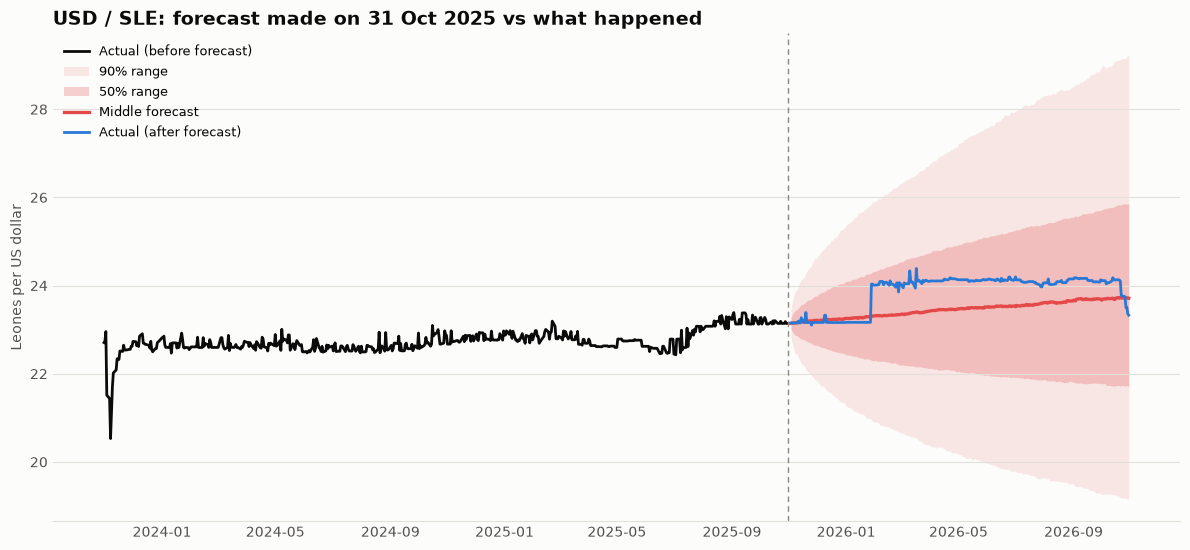

In [107]:
RED = "#e34948"


def style(ax):
    ax.set_facecolor(SURFACE)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.tick_params(colors=MUTED, labelcolor=INK2, length=0)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)


def fan(ax, dates, paths, history, actual_s=None):
    pct = percentile_table(paths, dates)
    ax.plot(history.index, history.values, color=INK, linewidth=2, label="Actual (before forecast)")
    ax.fill_between(dates, pct["p5"], pct["p95"], color=RED, alpha=0.12, linewidth=0, label="90% range")
    ax.fill_between(dates, pct["p25"], pct["p75"], color=RED, alpha=0.25, linewidth=0, label="50% range")
    ax.plot(dates, pct["p50"], color=RED, linewidth=2.4, label="Middle forecast")
    if actual_s is not None:
        ax.plot(actual_s.index, actual_s.values, color=SERIES, linewidth=2, label="Actual (after forecast)")
    ax.axvline(history.index[-1], color=MUTED, linewidth=1, linestyle=(0, (4, 3)))
    style(ax)
    return pct


fig, ax = plt.subplots(figsize=(12, 5.6), facecolor=SURFACE)
fan(ax, actual_s.index, test_paths["Inflation model"], s_bd[o_test - pd.DateOffset(years=2):o_test], actual_s)
ax.set_title(f"USD / SLE: forecast made on {o_test:%d %b %Y} vs what happened", loc="left",
             fontsize=14, fontweight="bold", color=INK)
ax.set_ylabel("Leones per US dollar", color=INK2)
ax.legend(loc="upper left", frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig(DATA_DIR / "test_usd_sle_2025_26.png", dpi=170, facecolor=SURFACE)
plt.show()

## 11. Backtest: 28 quarterly forecast dates, Dec 2017 – Sep 2024

One test year can be luck. Here we repeat the exact same procedure on 28 past dates: fit on data up to that date
(inflation = previous calendar-year average), forecast 252 trading days, score against what happened.

**How to read it:**
* If the inflation model has a lower error than *No drift*, the inflation trend carries real information.
* Coverage near 90% means the range is honest. Far below 90% = overconfident; near 100% with a very wide range = too cautious.
* Results by year show *when* the model fails (e.g. the 2022–23 depreciation), which is worth one sentence in the report.

In [108]:
BACKTEST_DATES = pd.date_range("2017-12-31", "2024-09-30", freq="QE")

rows = []
for d in BACKTEST_DATES:
    p_bt = calibrate(s_bd, d, backtest_inflation(d, "SLE"), backtest_inflation(d, "USD"))
    future = s_bd[s_bd.index > p_bt["origin"]].iloc[:TD].to_numpy()
    for name, paths in competitors(p_bt, len(future), n=2000).items():
        rows.append({"start": p_bt["origin"], "year": p_bt["origin"].year, "model": name,
                     "drift used (%/yr)": p_bt["mu"] * 100, **score(paths, future)})
backtest = pd.DataFrame(rows)

cols = ["average % error", "coverage of 90% range (%)", "12m range width (% of rate)", "CRPS at 12m (% of rate)"]
backtest.groupby("model")[cols].mean().round(2).sort_values("CRPS at 12m (% of rate)")

,average % error,coverage of 90% range (%),12m range width (% of rate),CRPS at 12m (% of rate)
model,,,,
No drift,7.85,72.42,48.96,12.31
Inflation model,8.05,75.21,48.96,13.06
No change,7.77,0.04,0.00,14.16


In [109]:
# Where does it fail? Average error by forecast year
backtest.pivot_table(index="year", columns="model", values="average % error", aggfunc="mean").round(1)

model,Inflation model,No change,No drift
year,,,
2017,2.4,4.6,4.9
2018,2.3,7.1,7.3
2019,3.2,4.3,4.4
2020,2.8,3.4,3.4
2021,7.4,11.8,11.8
2022,18.2,20.6,20.7
2023,7.6,5.5,5.5
2024,19.0,0.8,0.8


## 11b. Shock distribution: normal vs t-distribution vs bootstrap

Same drift (inflation), same data, only the shape of the daily surprises $\varepsilon_t$ changes (Step 4b).

* **Normal:** bell curve with volatility $\sigma$.
* **t-distribution:** same $\sigma$, fatter tails, $\nu$ estimated from kurtosis.
* **Block bootstrap:** real past 21-day blocks of daily moves, no assumed shape.

If the three score about the same, the simple normal model is enough (simplicity criterion). If t or bootstrap gives clearly better
coverage, fat tails matter for this currency and are worth one paragraph in the report.

In [110]:
SHOCKS = ["normal", "t", "bootstrap"]

rows = []
for kind in SHOCKS:
    rows.append({"shocks": kind, **score(simulate(p_test, DAYS, shocks=kind), actual)})
test_shock = pd.DataFrame(rows).set_index("shocks")

rows = []
for d in BACKTEST_DATES:
    p_bt = calibrate(s_bd, d, backtest_inflation(d, "SLE"), backtest_inflation(d, "USD"))
    future = s_bd[s_bd.index > p_bt["origin"]].iloc[:TD].to_numpy()
    for kind in SHOCKS:
        rows.append({"shocks": kind, **score(simulate(p_bt, len(future), n=2000, shocks=kind), future)})
bt_shock = pd.DataFrame(rows).groupby("shocks")[cols].mean().reindex(SHOCKS)

print(f"t degrees of freedom estimated on {o_test:%d %b %Y}: nu = {p_test['nu']:.1f}")
pd.concat({"2025-26 test": test_shock, "backtest average (28 dates)": bt_shock}).round(2)

t degrees of freedom estimated on 31 Oct 2025: nu = 4.1


average % error  \
                            shocks                       
2025-26 test                normal                1.86   
                            t                     1.97   
                            bootstrap             1.63   
backtest average (28 dates) normal                8.05   
                            t                     8.09   
                            bootstrap             8.31   

                                       coverage of 90% range (%)  \
                            shocks                                 
2025-26 test                normal                        100.00   
                            t                             100.00   
                            bootstrap                     100.00   
backtest average (28 dates) normal                         75.21   
                            t                              75.07   
                            bootstrap                      76.54   

                                       12m range width (% of rate)  \
                            shocks                                   
2025-26 test                normal                           42.34   
                            t                                42.01   
                            bootstrap                        40.42   
backtest average (28 dates) normal                           48.96   
                            t                                50.66   
                            bootstrap                        53.32   

                                       CRPS at 12m (% of rate)  
                            shocks                              
2025-26 test                normal                        3.14  
                            t                             3.12  
                            bootstrap                     2.90  
backtest average (28 dates) normal                       13.06  
                            t                            13.10  
                            bootstrap                    13.17

In [111]:
# Where do the three differ? Tails of a 1-day move vs the 12-month range (central limit theorem)
rows = {}
for kind in SHOCKS:
    paths = simulate(p_test, TD, shocks=kind)
    day1 = np.log(paths[:, 0] / p_test["s0"])
    end = paths[:, -1]
    rows[kind] = {"1-day move: excess kurtosis": float(pd.Series(day1).kurt()),
                  "1-day move: 99.9% quantile (%)": float(np.percentile(day1, 99.9) * 100),
                  "12m: 1%": float(np.percentile(end, 1)),
                  "12m: middle": float(np.median(end)),
                  "12m: 99%": float(np.percentile(end, 99)),
                  "touches +10% within a year": f"{(paths.max(axis=1) >= p_test['s0'] * 1.1).mean():.1%}"}
pd.DataFrame(rows).T.round(2)

,1-day move: excess kurtosis,1-day move: 99.9% quantile (%),12m: 1%,12m: middle,12m: 99%,touches +10% within a year
normal,0.030678,2.611331,17.626181,23.66621,31.903437,48.8%
t,5.047316,3.843879,17.536854,23.686539,31.510019,48.4%
bootstrap,215.532074,2.958085,16.424616,23.787224,30.214172,36.6%


**How to read it:** the 1-day columns differ a lot (t and bootstrap have fat daily tails), while the 12-month percentiles are close,
because 252 daily surprises add up to something near-normal. The bootstrap's 12-month range can still differ, because its volatility
comes straight from history rather than from $\sigma$.

# Part 4. Risk and liquidity

## 12. Stress scenario: sudden devaluations

The normal model has no sudden jumps. Frontier currencies sometimes devalue in a few days, so we add an
**optional** stress scenario, not estimated from data but chosen as a "what if":

$$r_t = (\mu - \lambda J)\,\Delta t + \sigma\sqrt{\Delta t}\,\varepsilon_t + J\cdot\mathbf 1\{\text{jump on day } t\}$$

* $\lambda$ = jumps per year (each day has probability $\lambda\Delta t$ of a jump)
* $J$ = log size of one jump ($\ln 1.15$ = a 15% devaluation)
* $-\lambda J$ keeps the **middle forecast at the inflation trend**: jumps make the tails fatter, they do not move the centre.

The old model estimated $\lambda$ and $J$ from the 2018–2023 crisis years and added them on top of the trend, which
pushed every forecast upwards. Keeping jumps as a labelled scenario avoids that bias.

In [112]:
STRESS_RATE = 0.5            # one 15% devaluation every two years on average
STRESS_SIZE = np.log(1.15)

LIVE_ORIGIN = s_bd.index[-1]
p_live = calibrate(s_bd, LIVE_ORIGIN, INFLATION_LIVE["SLE"][0], INFLATION_LIVE["USD"][0])
LIVE_DAYS = horizon_until(LIVE_ORIGIN, 1)
live_dates = future_dates(LIVE_ORIGIN, LIVE_DAYS)

live_base = simulate(p_live, LIVE_DAYS)
live_stress = simulate(p_live, LIVE_DAYS, jump_rate=STRESS_RATE, jump_size=STRESS_SIZE)

rows = {}
for name, paths in {"base model": live_base, f"stress: {STRESS_RATE} jumps/yr of 15%": live_stress}.items():
    end = paths[:, -1]
    rows[name] = {"5%": np.percentile(end, 5), "middle": np.median(end), "95%": np.percentile(end, 95),
                  "99%": np.percentile(end, 99),
                  "chance end > +20%": f"{(end > p_live['s0'] * 1.2).mean():.1%}"}
print(f"Start: {LIVE_ORIGIN:%d %b %Y}, rate {p_live['s0']:.3f}. End of horizon: {live_dates[-1]:%d %b %Y}")
pd.DataFrame(rows).T.round(2)

Start: 06 Nov 2026, rate 23.424. End of horizon: 05 Nov 2027


,5%,middle,95%,99%,chance end > +20%
base model,24.588612,26.224302,27.933813,28.638002,3.3%
stress: 0.5 jumps/yr of 15%,23.08441,25.331837,32.568611,37.352314,24.9%


## 13. Trigger probabilities

Two different questions for a level $L$ (e.g. 10% above today):

* **Ends above:** $P(S_T > L)$. Has a formula (Step 5).
* **Touches at any time:** $P(\max_{t\le T} S_t \ge L)$. Path-dependent, so only Monte Carlo can answer it: the share of paths whose maximum reaches $L$. Always ≥ "ends above".

A guarantee or hedge that is triggered the first time the rate crosses $L$ needs the second number.

In [113]:
T1 = LIVE_DAYS / TD
rows = []
for up in (0.05, 0.10, 0.20, 0.30):
    L = p_live["s0"] * (1 + up)
    z = (np.log(L / p_live["s0"]) - p_live["mu"] * T1) / (p_live["sigma"] * np.sqrt(T1))
    rows.append({"level": f"+{up:.0%}  ({L:.2f})",
                 "ends above: formula": f"{1 - norm.cdf(z):.1%}",
                 "ends above: Monte Carlo": f"{(live_base[:, -1] > L).mean():.1%}",
                 "touches at any time": f"{(live_base.max(axis=1) >= L).mean():.1%}",
                 "touches, stress scenario": f"{(live_stress.max(axis=1) >= L).mean():.1%}"})
pd.DataFrame(rows).set_index("level")

,ends above: formula,ends above: Monte Carlo,touches at any time,"touches, stress scenario"
level,,,,
+5% (24.60),95.1%,94.9%,97.2%,73.1%
+10% (25.77),67.3%,67.5%,72.6%,47.0%
+20% (28.11),3.5%,3.3%,4.1%,28.6%
+30% (30.45),0.0%,0.0%,0.0%,10.4%


## 14. Liquidity: can remittance flows be matched with investors' dollar needs?

**Set-up (check every input against the Concept Note and replace the placeholder numbers):**

* **Investors** earn leones in Sierra Leone and need to convert them into **$N$ US dollars** over the year at an agreed **hedge rate $K$**.
* **Remitters** send dollars home and are willing to sell **$V$ dollars per trading day** through the platform at the hedge rate, as long as the market
  rate is not much better for them, i.e. while $S_t \le K^*$ (the **matching trigger**, slightly above $K$).
* When $S_t > K^*$ the market pays remitters noticeably more leones than the platform, so they go to the market and no matching happens that day.

**Formulas (on each Monte Carlo path; probabilities = share of paths):**

$$\text{dollars matched} = \sum_{t=1}^{T} V\cdot\mathbf 1\{S_t \le K^*\},\qquad
\text{hedge completes} \iff \text{dollars matched} \ge N,\qquad
\text{shortfall} = \max(N - \text{dollars matched},\,0)$$

**Guarantee loss.** If the hedge is guaranteed, the guarantor pays the gap between the dollars promised and the dollars the investor's
leones $C = N\cdot K$ actually buy at the end:

$$\text{loss} = \max\!\left(\frac{C}{K} - \frac{C}{S_T},\; 0\right)$$

Intuition: the faster the leone weakens (higher $\mu$, bigger $\sigma$), the more days the market rate sits above the trigger, so
matching dries up exactly when the investor most needs the hedge. That is the liquidity risk.

In [114]:
NOTIONAL_USD = 1_000_000      # N: dollars investors need over the year      (placeholder)
DAILY_REMIT_USD = 10_000      # V: dollars remitters offer per trading day   (placeholder)
HEDGE_RATE = p_live["s0"]     # K: agreed conversion rate (here: today's rate)


def hedge_completion(paths, notional, daily, trigger):
    good_days = paths <= trigger
    cum = np.cumsum(good_days * daily, axis=1)
    filled = cum[:, -1]
    shortfall = np.clip(notional - filled, 0, None)
    reached = cum >= notional
    first_day = reached.argmax(axis=1) + 1
    days_to_fill = np.where(reached.any(axis=1), first_day, np.nan)
    return {"chance hedge completes": f"{(filled >= notional).mean():.1%}",
            "average shortfall (USD)": float(shortfall.mean()),
            "95% worst shortfall (USD)": float(np.percentile(shortfall, 95)),
            "median trading days to fill": float(np.nanmedian(days_to_fill)),
            "share of days with matching": f"{good_days.mean():.1%}"}


rows = []
for buffer in (0.00, 0.02, 0.05, 0.10):
    trigger = HEDGE_RATE * (1 + buffer)
    for name, paths in {"base": live_base, "stress": live_stress}.items():
        rows.append({"trigger K*": f"K +{buffer:.0%} ({trigger:.2f})", "scenario": name,
                     **hedge_completion(paths, NOTIONAL_USD, DAILY_REMIT_USD, trigger)})
print(f"N = ${NOTIONAL_USD:,.0f}, V = ${DAILY_REMIT_USD:,.0f}/day "
      f"(needs {NOTIONAL_USD / DAILY_REMIT_USD:.0f} matching days out of {LIVE_DAYS}), K = {HEDGE_RATE:.3f}")
pd.DataFrame(rows).set_index(["trigger K*", "scenario"]).round(0)

N = $1,000,000, V = $10,000/day (needs 100 matching days out of 260), K = 23.424


chance hedge completes  average shortfall (USD)  \
trigger K*     scenario                                                   
K +0% (23.42)  base                       2.2%                 857993.0   
               stress                    19.7%                 612646.0   
K +2% (23.89)  base                      15.3%                 468132.0   
               stress                    49.4%                 248552.0   
K +5% (24.60)  base                      59.5%                 110576.0   
               stress                    76.8%                 104432.0   
K +10% (25.77) base                      98.9%                   1276.0   
               stress                    82.3%                  90761.0   

                         95% worst shortfall (USD)  \
trigger K*     scenario                              
K +0% (23.42)  base                      1000000.0   
               stress                    1000000.0   
K +2% (23.89)  base                       860000.0   
               stress                     840000.0   
K +5% (24.60)  base                       500000.0   
               stress                     740500.0   
K +10% (25.77) base                            0.0   
               stress                     740000.0   

                         median trading days to fill  \
trigger K*     scenario                                
K +0% (23.42)  base                            112.0   
               stress                          121.0   
K +2% (23.89)  base                            100.0   
               stress                          100.0   
K +5% (24.60)  base                            100.0   
               stress                          100.0   
K +10% (25.77) base                            100.0   
               stress                          100.0   

                        share of days with matching  
trigger K*     scenario                              
K +0% (23.42)  base                            5.8%  
               stress                         20.3%  
K +2% (23.89)  base                           23.0%  
               stress                         45.1%  
K +5% (24.60)  base                           47.7%  
               stress                         66.6%  
K +10% (25.77) base                           80.4%  
               stress                         77.3%

In [115]:
def guarantee_loss(paths, notional, hedge_rate):
    cash_sle = notional * hedge_rate
    loss = np.clip(cash_sle / hedge_rate - cash_sle / paths[:, -1], 0, None)
    return {"chance guarantor pays": f"{(loss > 0).mean():.1%}",
            "expected loss (USD)": float(loss.mean()),
            "95% worst loss (USD)": float(np.percentile(loss, 95)),
            "expected loss (% of notional)": float(loss.mean() / notional * 100)}


rows = []
for up in (0.00, 0.05, 0.10):
    K = p_live["s0"] * (1 + up)
    for name, paths in {"base": live_base, "stress": live_stress}.items():
        rows.append({"hedge rate K": f"S0 +{up:.0%} ({K:.2f})", "scenario": name,
                     **guarantee_loss(paths, NOTIONAL_USD, K)})
pd.DataFrame(rows).set_index(["hedge rate K", "scenario"]).round(1)

chance guarantor pays  expected loss (USD)  \
hedge rate K    scenario                                              
S0 +0% (23.42)  base                     99.8%             105825.5   
                stress                   90.9%             104355.5   
S0 +5% (24.60)  base                     94.9%              61973.8   
                stress                   65.1%              70001.3   
S0 +10% (25.77) base                     67.5%              25025.6   
                stress                   44.6%              47830.4   

                          95% worst loss (USD)  expected loss (% of notional)  
hedge rate K    scenario                                                       
S0 +0% (23.42)  base                  161449.9                           10.6  
                stress                280782.9                           10.4  
S0 +5% (24.60)  base                  119522.4                            6.2  
                stress                244822.0                            7.0  
S0 +10% (25.77) base                   77594.9                            2.5  
                stress                208861.2                            4.8

**How to use these tables:** the expected loss is a fair annual **fee** for the guarantee (as % of notional);
the 95% worst loss is the **capital** the guarantor should hold. Setting $K$ above today's rate makes the guarantee
cheaper but the hedge less attractive to investors, the trade-off to discuss in the report.

# Part 5. Forecast

## 15. 12-month forecast from 6 Nov 2026

Fitted on all data up to the last day in the snapshot and on the latest published inflation figures.
Percentiles and the raw simulated paths are exported so the results can be reused without rerunning the notebook.

In [116]:
live_pct = percentile_table(live_base, live_dates)
lo_f, mid_f, hi_f = formula_bands(p_live, LIVE_DAYS)

monthly_rows = []
for k in range(M - 1, LIVE_DAYS, M):
    monthly_rows.append({"date": live_dates[k].date(), "5%": live_pct["p5"].iloc[k],
                         "middle": live_pct["p50"].iloc[k], "95%": live_pct["p95"].iloc[k],
                         "formula middle": mid_f[k]})

live_pct.to_csv(DATA_DIR / "forecast_usd_sle_12m_percentiles.csv")
np.save(DATA_DIR / "forecast_usd_sle_12m_paths.npy", live_base)
print(pd.Series(describe(p_live), name=f"fitted on data up to {LIVE_ORIGIN:%d %b %Y}").to_string())
print(f"\nSaved percentiles CSV and {live_base.shape[0]:,} x {live_base.shape[1]} paths to {DATA_DIR}/")
pd.DataFrame(monthly_rows).set_index("date").round(2)

start rate S0                         23.424
drift mu (% per yr)                    10.92
volatility sigma (% per yr)              3.8
t degrees of freedom nu                  4.6
12m middle forecast                   26.125
12m 90% range                  24.54 - 27.81

Saved percentiles CSV and 10,000 x 260 paths to data/


,5%,middle,95%,formula middle
date,,,,
2026-12-07,23.21,23.65,24.07,23.64
2027-01-05,23.25,23.86,24.48,23.85
2027-02-03,23.32,24.08,24.85,24.07
2027-03-04,23.42,24.30,25.19,24.29
2027-04-02,23.53,24.53,25.53,24.51
2027-05-03,23.66,24.75,25.87,24.74
2027-06-01,23.80,24.98,26.20,24.96
2027-06-30,23.93,25.21,26.53,25.19
2027-07-29,24.07,25.43,26.85,25.42


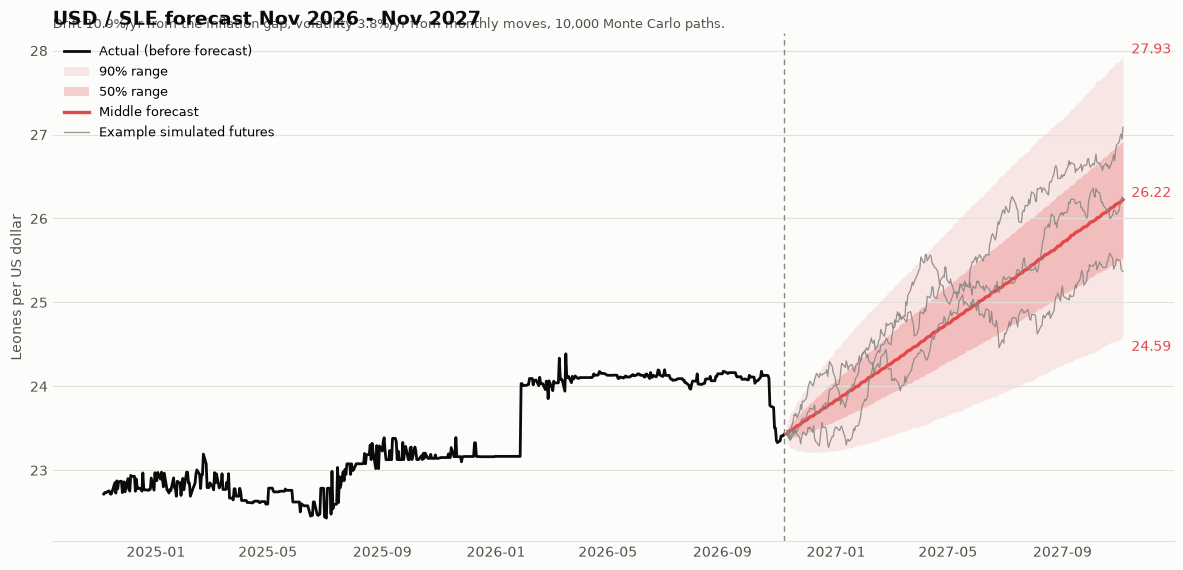

In [117]:
fig, ax = plt.subplots(figsize=(12, 5.8), facecolor=SURFACE)
pct = fan(ax, live_dates, live_base, s_bd[LIVE_ORIGIN - pd.DateOffset(years=2):])
ends = live_base[:, -1]
for q in (20, 50, 80):
    idx = int(np.argmin(np.abs(ends - np.percentile(ends, q))))
    label = None
    if q == 20:
        label = "Example simulated futures"
    ax.plot(live_dates, live_base[idx], color=MUTED, linewidth=0.9, alpha=0.9, label=label)
for col, dy in (("p95", 2), ("p50", 2), ("p5", -10)):
    ax.annotate(f"{pct[col].iloc[-1]:.2f}", (live_dates[-1], pct[col].iloc[-1]), xytext=(6, dy),
                textcoords="offset points", fontsize=10, color=RED)
ax.set_title(f"USD / SLE forecast {LIVE_ORIGIN:%b %Y} - {live_dates[-1]:%b %Y}", loc="left",
             fontsize=14, fontweight="bold", color=INK)
ax.text(0, 1.01, f"Drift {p_live['mu']:.1%}/yr from the inflation gap, volatility {p_live['sigma']:.1%}/yr from monthly moves, "
                 f"{N_PATHS:,} Monte Carlo paths.", transform=ax.transAxes, fontsize=9.5, color=INK2)
ax.set_ylabel("Leones per US dollar", color=INK2)
ax.legend(loc="upper left", frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig(DATA_DIR / "forecast_usd_sle_12m.png", dpi=170, facecolor=SURFACE)
plt.show()

## 16. Longer horizon: 5 years

Same model, same inputs. The range widens with $\sqrt{T}$ and the centre follows $S_0 e^{\mu T}$.
Beyond one year this is a **scenario range**, because it assumes today's inflation gap lasts for 5 years.

In [118]:
LONG_YEARS = 5
long_days = horizon_until(LIVE_ORIGIN, LONG_YEARS)
long_dates = future_dates(LIVE_ORIGIN, long_days)
long_paths = simulate(p_live, long_days, n=5000)
long_pct = percentile_table(long_paths, long_dates)

rows = []
for yrs in range(1, LONG_YEARS + 1):
    k = min(horizon_until(LIVE_ORIGIN, yrs), long_days) - 1
    T = (k + 1) / TD
    rows.append({"after": f"{yrs} yr", "date": long_dates[k].date(),
                 "5%": long_pct["p5"].iloc[k], "middle": long_pct["p50"].iloc[k], "95%": long_pct["p95"].iloc[k],
                 "formula middle S0*exp(mu*T)": p_live["s0"] * np.exp(p_live["mu"] * T)})
long_pct.to_csv(DATA_DIR / "forecast_usd_sle_5y_percentiles.csv")
pd.DataFrame(rows).set_index("after").round(2)

,date,5%,middle,95%,formula middle S0*exp(mu*T)
after,,,,,
1 yr,2027-11-05,24.59,26.24,27.98,26.22
2 yr,2028-11-06,26.78,29.36,32.22,29.35
3 yr,2029-11-06,29.38,32.91,36.79,32.87
4 yr,2030-11-06,32.33,36.83,41.84,36.80
5 yr,2031-11-06,35.66,41.32,47.54,41.21


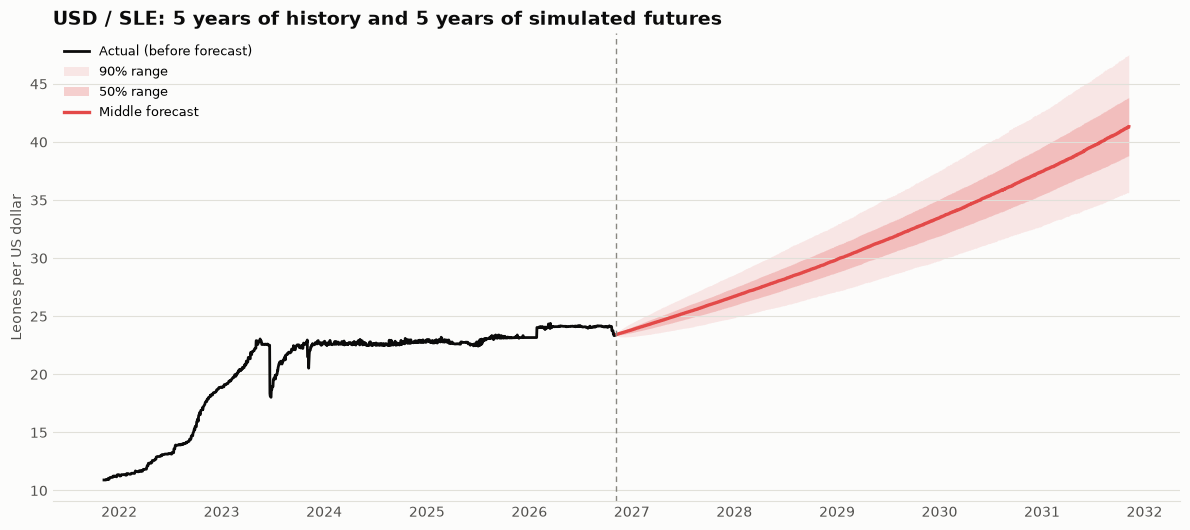

In [119]:
fig, ax = plt.subplots(figsize=(12, 5.4), facecolor=SURFACE)
fan(ax, long_dates, long_paths, s_bd[LIVE_ORIGIN - pd.DateOffset(years=5):])
ax.set_title("USD / SLE: 5 years of history and 5 years of simulated futures", loc="left",
             fontsize=14, fontweight="bold", color=INK)
ax.set_ylabel("Leones per US dollar", color=INK2)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.legend(loc="upper left", frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig(DATA_DIR / "forecast_usd_sle_5y.png", dpi=170, facecolor=SURFACE)
plt.show()

# Part 6. Other currencies

## 17. Same code, different currency

To move the model to a new currency you need exactly **two inputs**: a daily price file and one inflation number.
Nothing is re-tuned. Below: the same 31 Oct 2025 test for Ghana (GHS), Nigeria (NGN) and Kenya (KES), next to SLE.

What to expect: the model forecasts the *inflation trend*. Where a currency moved for other reasons in 2025–26
(an IMF programme, a policy reset, a commodity windfall), the actual path can leave the middle forecast; the
question is whether it stays inside the 90% range. That is what coverage measures.

In [120]:
OTHER = {"GHS": "Ghanaian cedi", "NGN": "Nigerian naira", "KES": "Kenyan shilling"}


def load_pair(target):
    # Daily USD->target rates from Wise, cleaned and cut to trading days up to DATA_END.
    raw = DATA_DIR / f"usd_{target.lower()}_wise_raw.csv"
    if REFRESH or not raw.exists():
        download_wise_csv("USD", target, raw)
    df = pd.read_csv(raw, parse_dates=["date"])
    px = df.dropna(subset=["close"]).groupby("date")["close"].last().sort_index()
    px.name = target
    px = despike(px)
    return px[px.index.dayofweek < 5][:DATA_END]


series = {"SLE": s_bd}
for code_ in OTHER:
    try:
        series[code_] = load_pair(code_)
    except (requests.RequestException, ValueError, KeyError) as err:
        print(f"  {code_}: skipped ({err})")

for code_ in series:
    if code_ == "SLE":
        continue
    raw = DATA_DIR / f"usd_{code_.lower()}_wise_raw.csv"
    known = manifest["files"].get(raw.name)
    if known is None or REFRESH:
        manifest["files"][raw.name] = file_info(raw)
        MANIFEST.write_text(json.dumps(manifest, indent=2))
    elif sha256(raw) != known["sha256"]:
        raise RuntimeError(f"{raw.name} differs from the frozen snapshot.")

  GHS: dropped 1 spikes
  NGN: dropped 6 spikes
  KES: dropped 0 spikes


In [121]:
test_rows, live_rows, panels = [], [], {}
for code_, px in series.items():
    p = calibrate(px, TEST_ORIGIN, INFLATION_TEST[code_][0], INFLATION_TEST["USD"][0])
    act = px[(px.index > p["origin"]) & (px.index <= TEST_END)]
    paths = competitors(p, len(act), n=5000)
    for name, pth in paths.items():
        test_rows.append({"currency": code_, "model": name, **score(pth, act.to_numpy())})
    panels[code_] = (p, act, paths["Inflation model"])

    q = calibrate(px, LIVE_ORIGIN, INFLATION_LIVE[code_][0], INFLATION_LIVE["USD"][0])
    live_rows.append({"currency": code_, **describe(q)})

pd.DataFrame(test_rows).set_index(["currency", "model"]).round(2)

average % error  coverage of 90% range (%)  \
currency model                                                         
SLE      Inflation model             1.82                      100.0   
         No drift                    2.82                      100.0   
         No change                   3.00                        0.0   
GHS      Inflation model             1.97                      100.0   
         No drift                    3.04                      100.0   
         No change                   3.45                        0.0   
NGN      Inflation model            12.97                      100.0   
         No drift                    5.33                      100.0   
         No change                   4.65                        0.0   
KES      Inflation model             0.86                      100.0   
         No drift                    0.18                      100.0   
         No change                   0.20                        0.0   

                          12m range width (% of rate)  CRPS at 12m (% of rate)  
currency model                                                                  
SLE      Inflation model                        42.18                     3.13  
         No drift                               42.18                     2.99  
         No change                               0.00                     0.81  
GHS      Inflation model                       116.43                     8.01  
         No drift                              116.43                     8.02  
         No change                               0.00                     6.60  
NGN      Inflation model                       163.06                    17.47  
         No drift                              163.06                    12.14  
         No change                               0.00                     6.68  
KES      Inflation model                        32.85                     2.41  
         No drift                               32.85                     2.34  
         No change                               0.00                     0.62

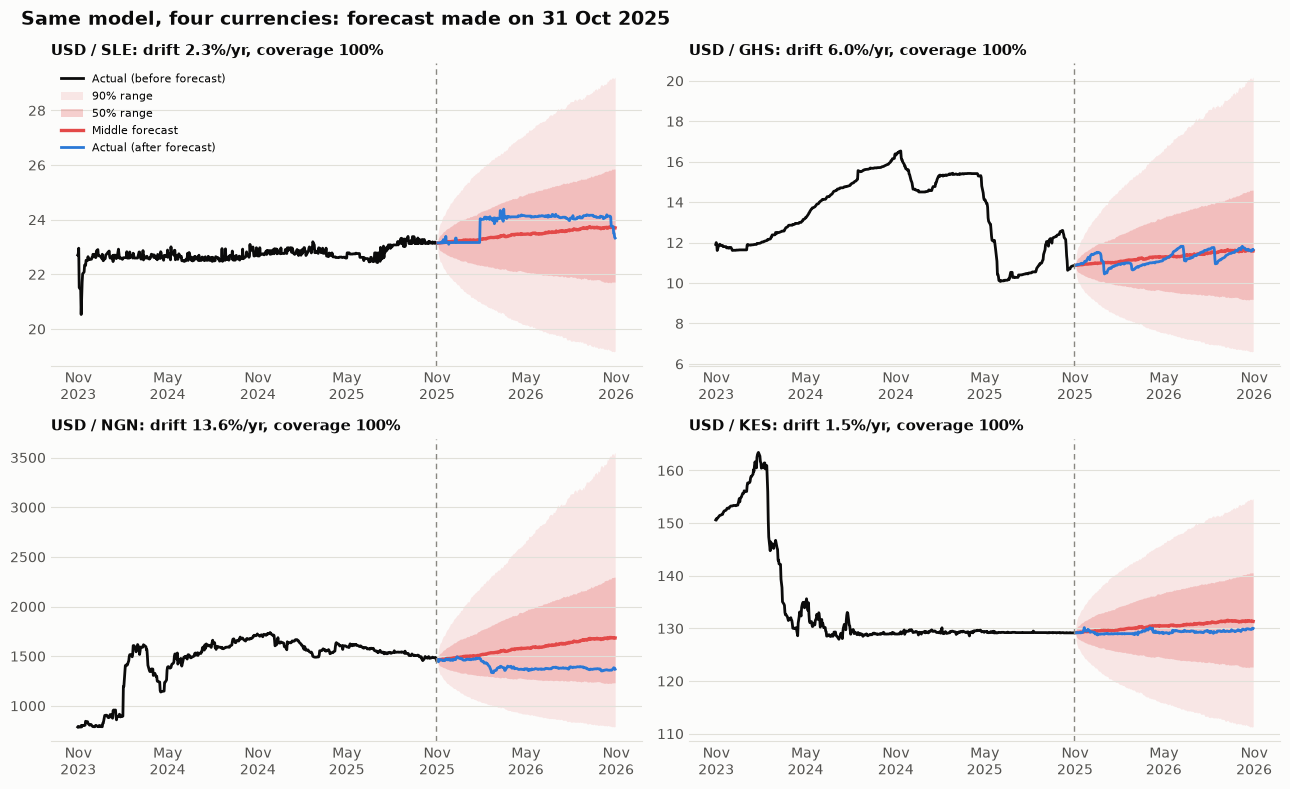

Live 12-month forecasts (from 6 Nov 2026):


,start rate S0,drift mu (% per yr),volatility sigma (% per yr),t degrees of freedom nu,12m middle forecast,12m 90% range
currency,,,,,,
SLE,23.424,10.92,3.80,4.6,26.125,24.54 - 27.81
GHS,11.675,1.72,23.61,4.3,11.878,8.06 - 17.51
NGN,1372.030,10.02,35.35,4.1,1516.642,847.85 - 2712.98
KES,129.900,3.41,8.85,4.3,134.410,116.20 - 155.48


In [122]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8), facecolor=SURFACE)
for ax, (code_, (p, act, paths)) in zip(axes.ravel(), panels.items()):
    px = series[code_]
    fan(ax, act.index, paths, px[p["origin"] - pd.DateOffset(years=2):p["origin"]], act)
    sc = score(paths, act.to_numpy())
    ax.set_title(f"USD / {code_}: drift {p['mu']:.1%}/yr, coverage {sc['coverage of 90% range (%)']:.0f}%",
                 loc="left", fontsize=11, fontweight="bold", color=INK)
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
axes[0, 0].legend(loc="upper left", frameon=False, fontsize=8)
fig.suptitle(f"Same model, four currencies: forecast made on {TEST_ORIGIN:%d %b %Y}", x=0.02, ha="left",
             fontsize=14, fontweight="bold", color=INK)
fig.tight_layout()
fig.savefig(DATA_DIR / "test_four_currencies.png", dpi=170, facecolor=SURFACE)
plt.show()

print("Live 12-month forecasts (from 6 Nov 2026):")
pd.DataFrame(live_rows).set_index("currency")

# Part 7. Limits

## 18. Recalibration checklist (for any currency, any date)

1. Put the daily price file in `data/` (or set `REFRESH = True` once to download it).
2. Look up the latest published consumer price inflation for the country and for the US; add both to `INFLATION_LIVE` with the source.
3. Run all cells. `calibrate()` recomputes $\mu$ and $\sigma$; nothing else changes.
4. Check Section 9: Monte Carlo and formula should agree to within a few hundredths.
5. Recalibrate monthly (new inflation print) or immediately after a regime change (new peg, devaluation, IMF programme).

## Known weaknesses (what a reviewer will ask)

* **Inflation is only a long-run anchor.** Over one year, currencies often move against the inflation gap (central bank intervention,
  aid inflows, a peg). The backtest-by-year table shows when this happened.
* **Constant inputs.** $\mu$ and $\sigma$ are fixed for the whole horizon. Over 5 years inflation will change, so the 5-year range is a scenario.
* **Volatility window choice.** 3 years includes the 2023 depreciation for SLE, so the range may be wide; a 2-year window is a reasonable
  sensitivity check (`vol_years=2`).
* **No jumps in the base model.** Sudden devaluations are handled only as a stress scenario (Section 12) with chosen, not estimated, inputs.
* **Mid-market data.** Wise and Yahoo show mid-market rates; real conversion rates for remitters and investors include a spread,
  which the liquidity section ignores.
* **Liquidity inputs are placeholders.** $N$, $V$, $K$ and the trigger rule must be matched to the Concept Note before quoting numbers.